# Proyecto final: predicción de complicaciones por dengue pediátrico

**Objetivo:** entrenar y evaluar dos modelos de clasificación supervisada —regresión logística y red neuronal artificial— con la base de datos `MASTER_CHART_F1000Research.xlsx`.

El notebook es el archivo principal de entrenamiento. Al ejecutarlo, prepara los datos, entrena ambos modelos, calcula métricas y matrices de confusión, genera gráficas y guarda los modelos entrenados y una base de datos SQLite para que la aplicación web pueda utilizarlos.

> **Advertencia:** desarrollo académico. No utilizar para diagnóstico, tratamiento, triage ni decisiones clínicas. El artículo fuente indica que su sistema de puntuación requiere validación antes de su aplicación clínica.


## 1. Instalar e importar librerías

Si alguna librería no está instalada, descomenta y ejecuta la celda de instalación.

In [1]:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib

from pathlib import Path
import json
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42


## 2. Ubicar y cargar el archivo Excel

El archivo Excel debe estar en la misma carpeta del notebook. Se utiliza la hoja principal del libro.

In [2]:
BASE_DIR = Path.cwd()
# Si el notebook se abre desde otra carpeta, buscar el Excel dentro del directorio actual.
excel_candidates = list(BASE_DIR.glob("MASTER_CHART_F1000Research.xlsx"))
if not excel_candidates:
    excel_candidates = list(BASE_DIR.glob("**/MASTER_CHART_F1000Research.xlsx"))
if not excel_candidates:
    raise FileNotFoundError(
        "No se encontró MASTER_CHART_F1000Research.xlsx. "
        "Coloca el Excel en la misma carpeta del notebook."
    )

EXCEL_PATH = excel_candidates[0]
PROJECT_DIR = EXCEL_PATH.parent
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

df = pd.read_excel(EXCEL_PATH)
df.columns = [
    str(col).strip().replace(" ", "_").replace(":", "").replace("/", "_")
    for col in df.columns
]
print("Archivo:", EXCEL_PATH.name)
print("Dimensiones originales:", df.shape)
display(df.head())


Archivo: MASTER_CHART_F1000Research.xlsx
Dimensiones originales: (303, 25)


,GROUPS_DENGUE_FEVER_OR_COMPLICATED_DENGUE,AGE,GENDER,DURATION_OF_FEVER,HEADACHE,MYALGIA,ABDOMINAL_PAIN,RASH,VOMITING,BREATHLESSNESS,BLEEDING,BP_AT_ADMISSION,ORGANOMEGALY,HB,PCV,LOWEST_WBC,HIGHEST_WBC,PLATELET_COUNT,ALT,CREATININE,FERRITIN,IV_FLUIDS,ANTIBIOTICS,ANTIPYRETICS,STEROIDS
0,2,2,1,3,2,1,2,2,1,2,2,2,2,14.2,46.0,3400,5100,30000,53.0,0.62,4167.0,1,1,2,1
1,2,2,1,4,2,1,2,2,2,2,2,1,2,12.8,38.6,3000,5300,43000,21.0,0.43,108.0,1,2,2,2
2,1,1,2,3,2,1,2,2,2,2,2,1,2,11.7,35.5,2300,2600,129000,12.0,0.34,212.0,1,1,1,2
3,1,2,2,5,2,1,2,2,2,2,2,1,2,14.1,42.1,1500,4800,70000,171.0,0.80,1429.0,1,1,1,1
4,1,2,2,3,2,1,2,2,2,2,2,1,2,13.3,41.0,8600,9100,184000,45.0,0.44,NaN,1,2,1,2


## 3. Revisar estructura y calidad de los datos

La variable objetivo corresponde a la primera columna del Excel. En el diccionario, los grupos están codificados como `1 = dengue no complicado` y `2 = dengue complicado`.

In [3]:
TARGET = df.columns[0]
FEATURES = ["BP_AT_ADMISSION", "PCV", "PLATELET_COUNT", "HIGHEST_WBC", "ALT"]

missing_columns = [col for col in [TARGET] + FEATURES if col not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas esperadas en el Excel: {missing_columns}")

print("Variable objetivo:", TARGET)
print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))
print("\nValores faltantes:")
display(df[[TARGET] + FEATURES].isna().sum().to_frame("faltantes"))
print("\nDistribución de la variable objetivo:")
display(df[TARGET].value_counts(dropna=False).sort_index().to_frame("cantidad"))


Variable objetivo: GROUPS_DENGUE_FEVER_OR_COMPLICATED_DENGUE

Tipos de datos:


,tipo
GROUPS_DENGUE_FEVER_OR_COMPLICATED_DENGUE,int64
AGE,int64
GENDER,int64
DURATION_OF_FEVER,int64
HEADACHE,int64
MYALGIA,int64
ABDOMINAL_PAIN,int64
RASH,int64
VOMITING,int64
BREATHLESSNESS,int64



Valores faltantes:


,faltantes
GROUPS_DENGUE_FEVER_OR_COMPLICATED_DENGUE,0
BP_AT_ADMISSION,0
PCV,0
PLATELET_COUNT,0
HIGHEST_WBC,0
ALT,1



Distribución de la variable objetivo:


,cantidad
GROUPS_DENGUE_FEVER_OR_COMPLICATED_DENGUE,
1,240
2,63


## 4. Preparar variables y etiqueta

Se utilizan los cinco indicadores que el artículo identifica como predictores principales: hipotensión, PCV, plaquetas, WBC máximo y ALT.

**Interpretación de presión arterial:** el README adjunto describe códigos 1 y 2, pero no deja inequívoco cuál representa hipotensión. En el Excel, el código 2 aparece en 38 registros, que coincide con los 38 casos de hipotensión de la Tabla 1 del artículo (9 casos no complicados + 29 complicados). Por esa correspondencia, este proyecto interpreta `2 = hipotensión` y `1 = sin hipotensión`. Es una inferencia respaldada por las frecuencias, no una confirmación directa del diccionario; debe documentarse al presentar el trabajo.

Se excluyen filas sin etiqueta o sin alguno de los cinco indicadores requeridos. El artículo reporta 303 pacientes; se espera conservar 302 registros si solo falta ALT en un registro.

In [4]:
data = df.dropna(subset=[TARGET] + FEATURES).copy()

# Convertir la presión arterial a variable binaria:
# 1 = hipotensión (código original 2); 0 = sin hipotensión (código original 1).
bp_values = set(pd.to_numeric(data["BP_AT_ADMISSION"], errors="coerce").dropna().unique())
if not bp_values.issubset({1, 2}):
    raise ValueError(f"Códigos inesperados en BP_AT_ADMISSION: {bp_values}")
data["BP_AT_ADMISSION"] = (
    pd.to_numeric(data["BP_AT_ADMISSION"], errors="coerce") == 2
).astype(int)

X = data[FEATURES].apply(pd.to_numeric, errors="coerce")
y = (pd.to_numeric(data[TARGET], errors="coerce") == 2).astype(int)

if y.nunique() != 2:
    raise ValueError("La variable objetivo debe contener los códigos 1 y 2.")
if y.value_counts().min() < 2:
    raise ValueError("Se necesitan al menos dos observaciones de cada clase.")

print("Registros originales:", len(df))
print("Registros utilizados:", len(data))
print("Registros excluidos:", len(df) - len(data))
print("Distribución objetivo (0=no complicado, 1=complicado):")
display(y.value_counts().sort_index().rename(index={0:"No complicado",1:"Complicado"}).to_frame("cantidad"))
display(X.head())


Registros originales: 303
Registros utilizados: 302
Registros excluidos: 1
Distribución objetivo (0=no complicado, 1=complicado):


,cantidad
GROUPS_DENGUE_FEVER_OR_COMPLICATED_DENGUE,
No complicado,239
Complicado,63


,BP_AT_ADMISSION,PCV,PLATELET_COUNT,HIGHEST_WBC,ALT
0,1,46.0,30000,5100,53.0
1,0,38.6,43000,5300,21.0
2,0,35.5,129000,2600,12.0
3,0,42.1,70000,4800,171.0
4,0,41.0,184000,9100,45.0


## 5. Separar entrenamiento y prueba

Se reserva el 25 % de los datos para la evaluación final. La separación es estratificada para mantener la proporción de casos complicados y no complicados.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Entrenamiento:", X_train.shape[0], "registros")
print("Prueba:", X_test.shape[0], "registros")


Entrenamiento: 226 registros
Prueba: 76 registros


## 6. Construir y entrenar los modelos

Ambos modelos utilizan imputación por mediana y estandarización de las variables numéricas. La regresión logística utiliza ponderación balanceada de clases. La red neuronal es un perceptrón multicapa (MLP) con dos capas ocultas de 16 y 8 neuronas.

In [6]:
models = {
    "Regresión logística": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Red neuronal artificial": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(16, 8),
            activation="relu",
            solver="lbfgs",
            alpha=0.01,
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: entrenamiento completado")


Regresión logística: entrenamiento completado
Red neuronal artificial: entrenamiento completado


## 7. Evaluar desempeño y generar matrices de confusión

Las métricas de precisión, sensibilidad y F1 se calculan para la clase positiva (`1 = dengue complicado`). La exactitud mide el porcentaje total de clasificaciones correctas. ROC-AUC evalúa la capacidad de ordenar los casos positivos por encima de los negativos.

In [7]:
metrics = {}
matrices = {}
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = {"y_pred": y_pred, "y_prob": y_prob}
    metrics[name] = {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall": float(recall_score(y_test, y_pred, zero_division=0)),
        "f1": float(f1_score(y_test, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, y_prob)),
        "test_records": int(len(y_test))
    }
    matrices[name] = confusion_matrix(y_test, y_pred, labels=[0, 1]).tolist()

metrics_df = pd.DataFrame(metrics).T
display(metrics_df.style.format("{:.3f}"))
for name in models:
    print("\n", name)
    print(classification_report(
        y_test, predictions[name]["y_pred"],
        labels=[0, 1],
        target_names=["No complicado", "Complicado"],
        zero_division=0
    ))


,accuracy,precision,recall,f1,roc_auc,test_records
Regresión logística,0.816,0.536,0.938,0.682,0.922,76.000
Red neuronal artificial,0.868,0.667,0.750,0.706,0.867,76.000



 Regresión logística


               precision    recall  f1-score   support

No complicado       0.98      0.78      0.87        60
   Complicado       0.54      0.94      0.68        16

     accuracy                           0.82        76
    macro avg       0.76      0.86      0.78        76
 weighted avg       0.89      0.82      0.83        76


 Red neuronal artificial
               precision    recall  f1-score   support

No complicado       0.93      0.90      0.92        60
   Complicado       0.67      0.75      0.71        16

     accuracy                           0.87        76
    macro avg       0.80      0.82      0.81        76
 weighted avg       0.88      0.87      0.87        76



## 8. Visualizar métricas y matrices de confusión

La diagonal de cada matriz representa las predicciones correctas; las celdas fuera de la diagonal representan errores.

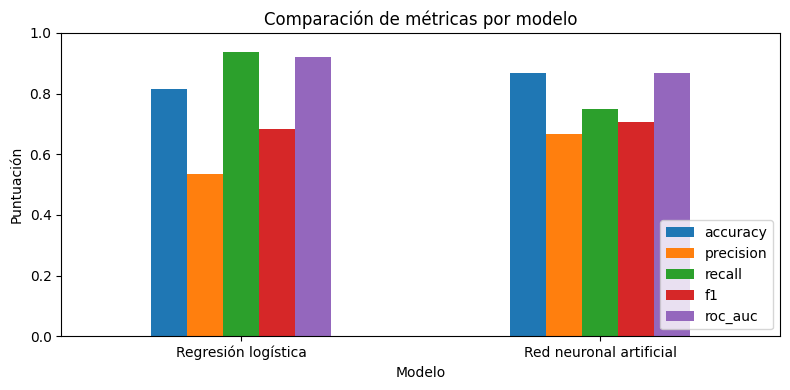

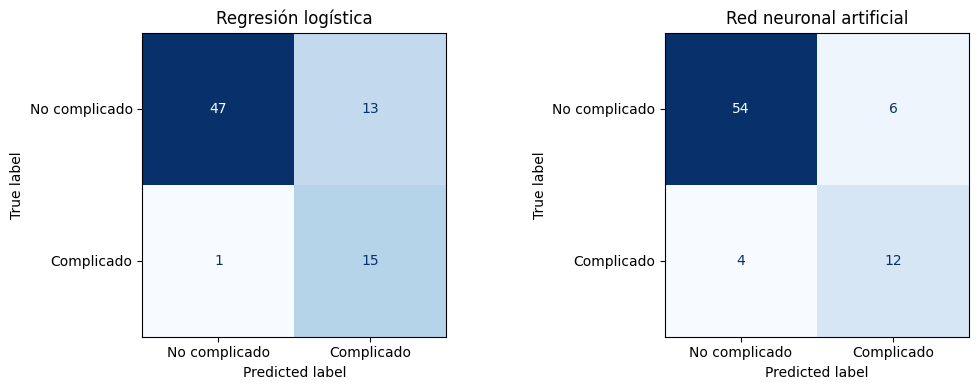

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
metrics_df[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot(
    kind="bar", ax=ax
)
ax.set_title("Comparación de métricas por modelo")
ax.set_ylabel("Puntuación")
ax.set_ylim(0, 1)
ax.set_xlabel("Modelo")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, models.keys()):
    ConfusionMatrixDisplay(
        confusion_matrix=np.array(matrices[name]),
        display_labels=["No complicado", "Complicado"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.show()


## 9. Curvas ROC

La curva ROC permite comparar sensibilidad frente a tasa de falsos positivos para distintos umbrales. El AUC se interpreta como una medida de discriminación, no como garantía de utilidad clínica.

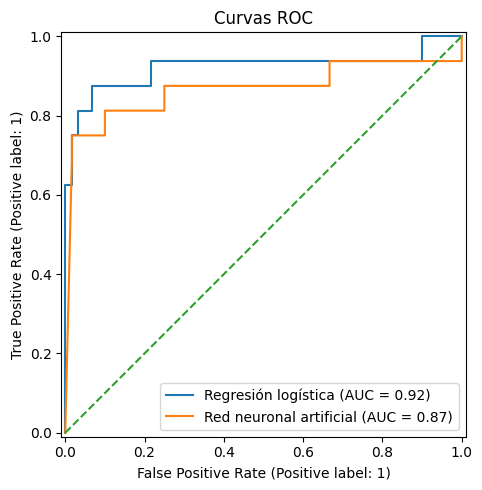

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], linestyle="--", label="Clasificador aleatorio")
ax.set_title("Curvas ROC")
plt.tight_layout()
plt.show()


## 10. Guardar modelos entrenados

Se genera `models/modelos_entrenados.joblib`, que es el artefacto utilizado por la aplicación web. También se guarda un informe JSON con métricas y matrices.

In [10]:
bundle = {
    "models": models,
    "features": FEATURES,
    "target": TARGET,
    "metrics": metrics,
    "matrices": matrices,
    "bp_mapping": (
        "Código original 2 = hipotensión y 1 = sin hipotensión, "
        "inferido al coincidir las frecuencias del Excel con la Tabla 1 del artículo."
    )
}
model_path = MODEL_DIR / "modelos_entrenados.joblib"
joblib.dump(bundle, model_path)

report = {
    "source_excel": EXCEL_PATH.name,
    "rows_original": int(len(df)),
    "rows_used": int(len(data)),
    "rows_excluded": int(len(df) - len(data)),
    "features": FEATURES,
    "target": TARGET,
    "class_mapping": {"0": "Dengue no complicado", "1": "Dengue complicado"},
    "split": "75% entrenamiento / 25% prueba, estratificado, random_state=42",
    "bp_mapping": bundle["bp_mapping"],
    "metrics": metrics,
    "confusion_matrices": matrices
}
with open(PROJECT_DIR / "informe_entrenamiento.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("Modelo guardado en:", model_path)
print("Informe guardado en:", PROJECT_DIR / "informe_entrenamiento.json")


Modelo guardado en: /mnt/data/Proyecto_Dengue_PredictLab/models/modelos_entrenados.joblib
Informe guardado en: /mnt/data/Proyecto_Dengue_PredictLab/informe_entrenamiento.json


## 11. Crear o actualizar la base de datos SQLite

La base de datos guarda los registros utilizados, las métricas de entrenamiento y las predicciones que realice la aplicación web. Si ya existe `dengue.db`, se actualizan las tablas de pacientes y métricas y se conserva el historial de predicciones.

In [11]:
db_path = PROJECT_DIR / "dengue.db"
conn = sqlite3.connect(db_path)
conn.execute("""
CREATE TABLE IF NOT EXISTS patients (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    original_row INTEGER NOT NULL,
    target INTEGER NOT NULL,
    features_json TEXT NOT NULL,
    original_json TEXT NOT NULL
)
""")
conn.execute("""
CREATE TABLE IF NOT EXISTS model_metrics (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    model_name TEXT NOT NULL,
    accuracy REAL, precision REAL, recall REAL, f1 REAL, roc_auc REAL,
    test_records INTEGER, confusion_matrix_json TEXT,
    trained_at TEXT DEFAULT CURRENT_TIMESTAMP
)
""")
conn.execute("""
CREATE TABLE IF NOT EXISTS predictions (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    mode TEXT NOT NULL,
    model_name TEXT NOT NULL,
    input_json TEXT NOT NULL,
    prediction INTEGER NOT NULL,
    probability REAL,
    created_at TEXT DEFAULT CURRENT_TIMESTAMP
)
""")

conn.execute("DELETE FROM patients")
conn.execute("DELETE FROM model_metrics")

for idx, row in data.iterrows():
    original = {
        k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
        for k, v in row.to_dict().items()
    }
    features_json = {
        k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
        for k, v in X.loc[idx].to_dict().items()
    }
    conn.execute(
        "INSERT INTO patients(original_row,target,features_json,original_json) VALUES(?,?,?,?)",
        (int(idx) + 2, int(y.loc[idx]),
         json.dumps(features_json, ensure_ascii=False),
         json.dumps(original, ensure_ascii=False))
    )

for name, m in metrics.items():
    conn.execute(
        """INSERT INTO model_metrics
        (model_name,accuracy,precision,recall,f1,roc_auc,test_records,confusion_matrix_json)
        VALUES(?,?,?,?,?,?,?,?)""",
        (name, m["accuracy"], m["precision"], m["recall"], m["f1"],
         m["roc_auc"], m["test_records"], json.dumps(matrices[name]))
    )

conn.commit()
print("Pacientes guardados:", conn.execute("SELECT COUNT(*) FROM patients").fetchone()[0])
print("Modelos evaluados:", conn.execute("SELECT COUNT(*) FROM model_metrics").fetchone()[0])
print("Base de datos:", db_path)
conn.close()


Pacientes guardados: 302
Modelos evaluados: 2
Base de datos: /mnt/data/Proyecto_Dengue_PredictLab/dengue.db


## 12. Probar una predicción de ejemplo

Este registro ficticio sirve únicamente para comprobar que los modelos responden. No representa a un paciente real.

In [12]:
ejemplo = pd.DataFrame([{
    "BP_AT_ADMISSION": 1,   # 1 = hipotensión en la codificación binaria interna
    "PCV": 45,
    "PLATELET_COUNT": 50000,
    "HIGHEST_WBC": 8000,
    "ALT": 100
}], columns=FEATURES)

for name, model in models.items():
    pred = int(model.predict(ejemplo)[0])
    probability = float(model.predict_proba(ejemplo)[0, 1])
    label = "Dengue complicado" if pred == 1 else "Dengue no complicado"
    print(f"{name}: {label} | probabilidad estimada clase complicada: {probability:.1%}")


Regresión logística: Dengue complicado | probabilidad estimada clase complicada: 96.6%
Red neuronal artificial: Dengue complicado | probabilidad estimada clase complicada: 100.0%


## 13. Conclusiones y limitaciones

- Se entrenaron dos clasificadores supervisados con las cinco variables principales del estudio.
- La evaluación utiliza una única división estratificada de entrenamiento y prueba; no equivale a validación externa.
- La base original tiene 303 filas y se utilizaron 302 por la ausencia de ALT en un registro.
- La interpretación del código de presión arterial se infirió comparando las frecuencias del Excel con la Tabla 1 del artículo, porque el README no deja clara la correspondencia.
- El conjunto de datos es pequeño y procede de un estudio hospitalario concreto; el rendimiento puede cambiar en otras poblaciones.
- El artículo fuente señala que su puntuación requiere validación antes de su uso rutinario. Este modelo es exclusivamente académico y no debe usarse para decisiones médicas.

**Referencia:** Bhaskar, M., Mahalingam, S., M M, H., & Achappa, B. (2022). *Predictive scoring system for risk of complications in pediatric dengue infection*. F1000Research, 11, 446. https://doi.org/10.12688/f1000research.111214.1
